<a href="https://colab.research.google.com/github/hilalkaynarcali/goruntu-isleme/blob/main/gurultulu_fonk2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# Vektör boyutu
N = 128

# Sinüs parametreleri
genlik = 2
faz = np.pi / 4
periyot = 32

# Örnek indeksleri
n = np.arange(N)

# Temiz sinüs vektörü
vektor = genlik * np.sin(
    2 * np.pi * n / periyot + faz
)

print("Vektör boyutu:", len(vektor))
print("İlk 10 değer:", vektor[:10])

Vektör boyutu: 128
İlk 10 değer: [1.41421356 1.66293922 1.84775907 1.96157056 2.         1.96157056
 1.84775907 1.66293922 1.41421356 1.11114047]


In [ ]:
def gurultu_ekle(vektor, gurultu_orani):

    # Gürültü oranını kontrol et
    if not 0 <= gurultu_orani <= 1:
        raise ValueError("Gürültü oranı 0 ile 1 arasında olmalıdır!")

    # Vektörün maksimum mutlak genliği
    genlik = np.max(np.abs(vektor))

    # Gürültünün maksimum büyüklüğü
    gurultu_genligi = genlik * gurultu_orani

    # Her eleman için rastgele gürültü üret
    gurultu = np.random.uniform(
        -gurultu_genligi,
        gurultu_genligi,
        size=len(vektor)
    )

    # Gürültüyü vektöre ekle
    yeni_vektor = vektor + gurultu

    return yeni_vektor

In [ ]:
# Gürültü oranı
gurultu_orani = 0.3

# Fonksiyonu çağır
gurultulu_vektor = gurultu_ekle(
    vektor,
    gurultu_orani
)

print("Gürültü oranı:", gurultu_orani)

print("\nOrijinal vektör:")
print(vektor[:10])

print("\nGürültülü vektör:")
print(gurultulu_vektor[:10])

Gürültü oranı: 0.3

Orijinal vektör:
[1.41421356 1.66293922 1.84775907 1.96157056 2.         1.96157056
 1.84775907 1.66293922 1.41421356 1.11114047]

Gürültülü vektör:
[0.95074834 2.12893617 2.02299213 1.57396507 1.55598113 2.46963226
 1.54910635 1.96528824 1.74762588 1.21599347]


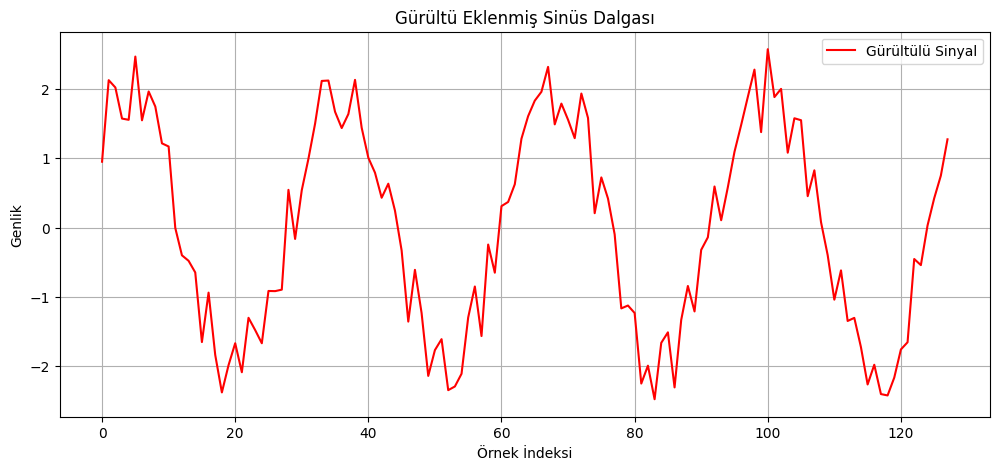

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(
    n,
    gurultulu_vektor,
    color="red",
    label="Gürültülü Sinyal"
)

plt.title("Gürültü Eklenmiş Sinüs Dalgası")
plt.xlabel("Örnek İndeksi")
plt.ylabel("Genlik")

plt.legend()
plt.grid(True)

plt.show()

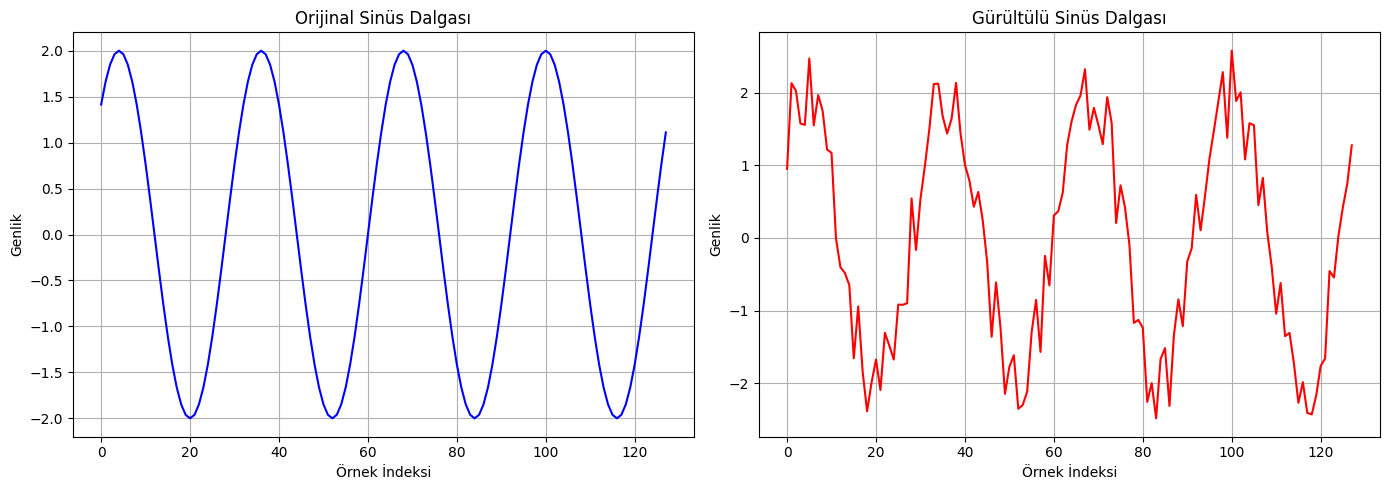

In [ ]:
plt.figure(figsize=(14, 5))

# Orijinal sinüs
plt.subplot(1, 2, 1)

plt.plot(n, vektor, color="blue")
plt.title("Orijinal Sinüs Dalgası")
plt.xlabel("Örnek İndeksi")
plt.ylabel("Genlik")
plt.grid(True)

# Gürültülü sinüs
plt.subplot(1, 2, 2)

plt.plot(n, gurultulu_vektor, color="red")
plt.title("Gürültülü Sinüs Dalgası")
plt.xlabel("Örnek İndeksi")
plt.ylabel("Genlik")
plt.grid(True)

plt.tight_layout()

plt.savefig("odev32_karsilastirma.png", dpi=200)

plt.show()

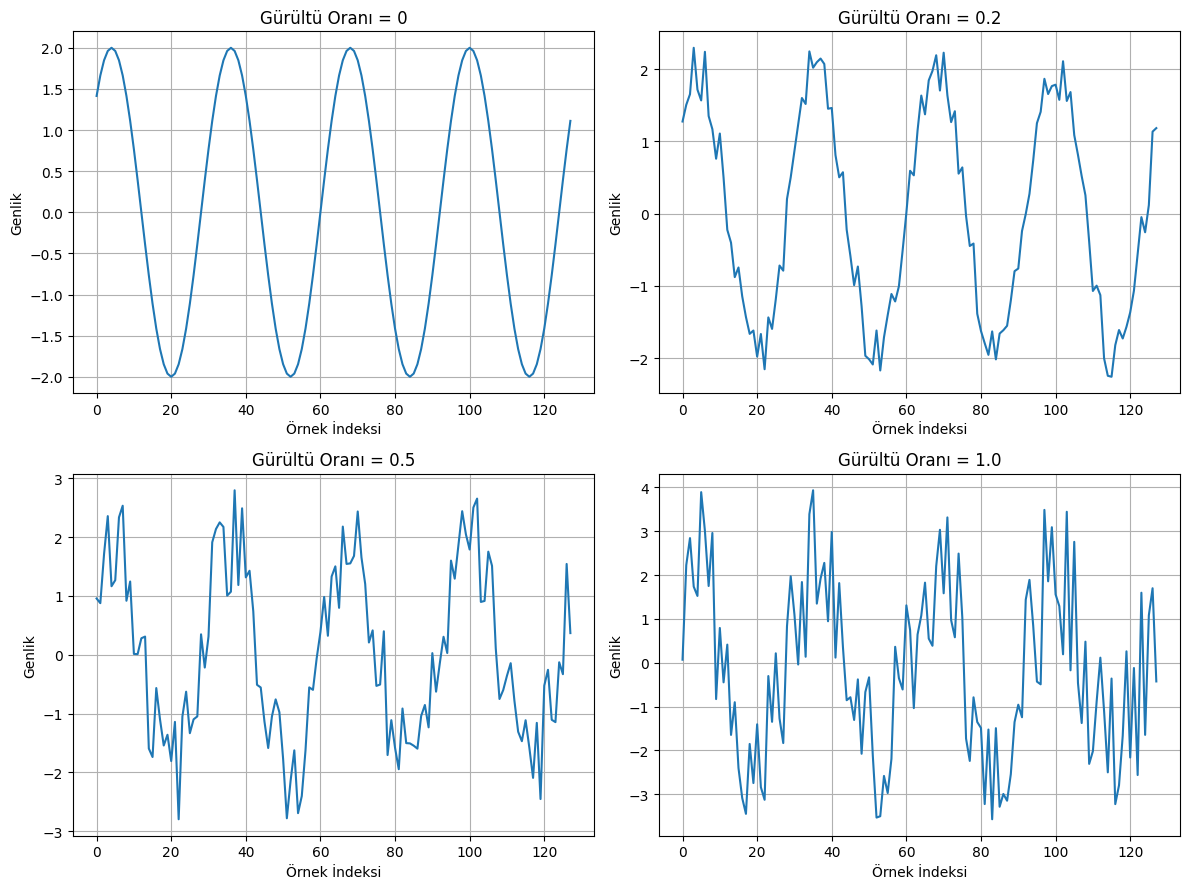

In [ ]:
oranlar = [0, 0.2, 0.5, 1.0]

plt.figure(figsize=(12, 9))

for i, oran in enumerate(oranlar):

    gurultulu = gurultu_ekle(vektor, oran)

    plt.subplot(2, 2, i + 1)

    plt.plot(n, gurultulu)

    plt.title(f"Gürültü Oranı = {oran}")
    plt.xlabel("Örnek İndeksi")
    plt.ylabel("Genlik")

    plt.grid(True)

plt.tight_layout()
plt.savefig("odev32_farkli_oranlar.png", dpi=200)

plt.show()

In [8]:
from scipy.ndimage import gaussian_filter1d, median_filter

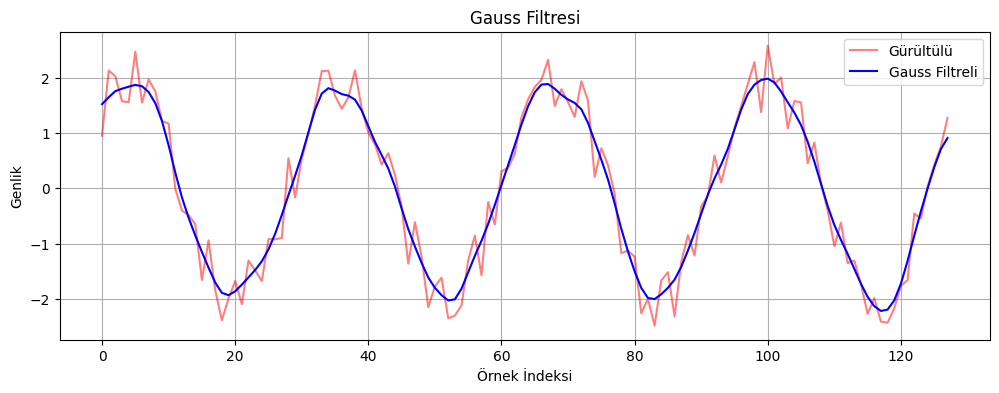

In [9]:
gauss = gaussian_filter1d(gurultulu_vektor, sigma=1.5)

plt.figure(figsize=(12, 4))

plt.plot(n, gurultulu_vektor, color="red", alpha=0.5, label="Gürültülü")
plt.plot(n, gauss, color="blue", label="Gauss Filtreli")

plt.title("Gauss Filtresi")
plt.xlabel("Örnek İndeksi")
plt.ylabel("Genlik")
plt.legend()
plt.grid(True)
plt.show()

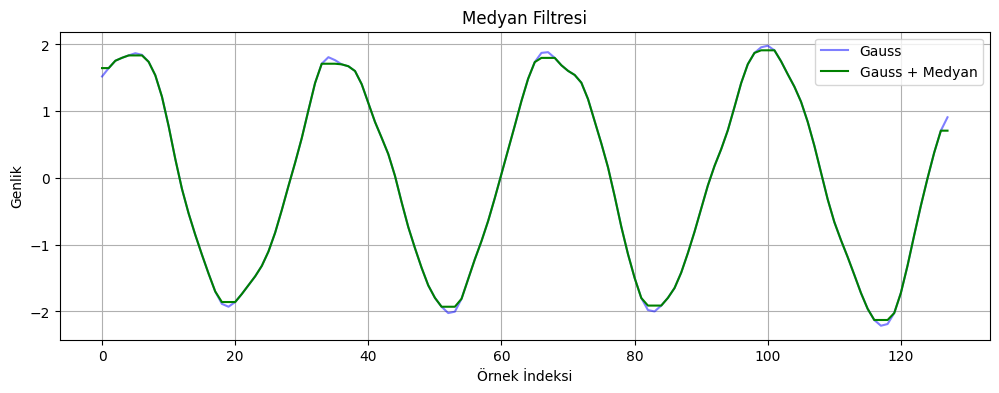

In [10]:
medyan = median_filter(gauss, size=5)

plt.figure(figsize=(12, 4))

plt.plot(n, gauss, color="blue", alpha=0.5, label="Gauss")
plt.plot(n, medyan, color="green", label="Gauss + Medyan")

plt.title("Medyan Filtresi")
plt.xlabel("Örnek İndeksi")
plt.ylabel("Genlik")
plt.legend()
plt.grid(True)
plt.show()

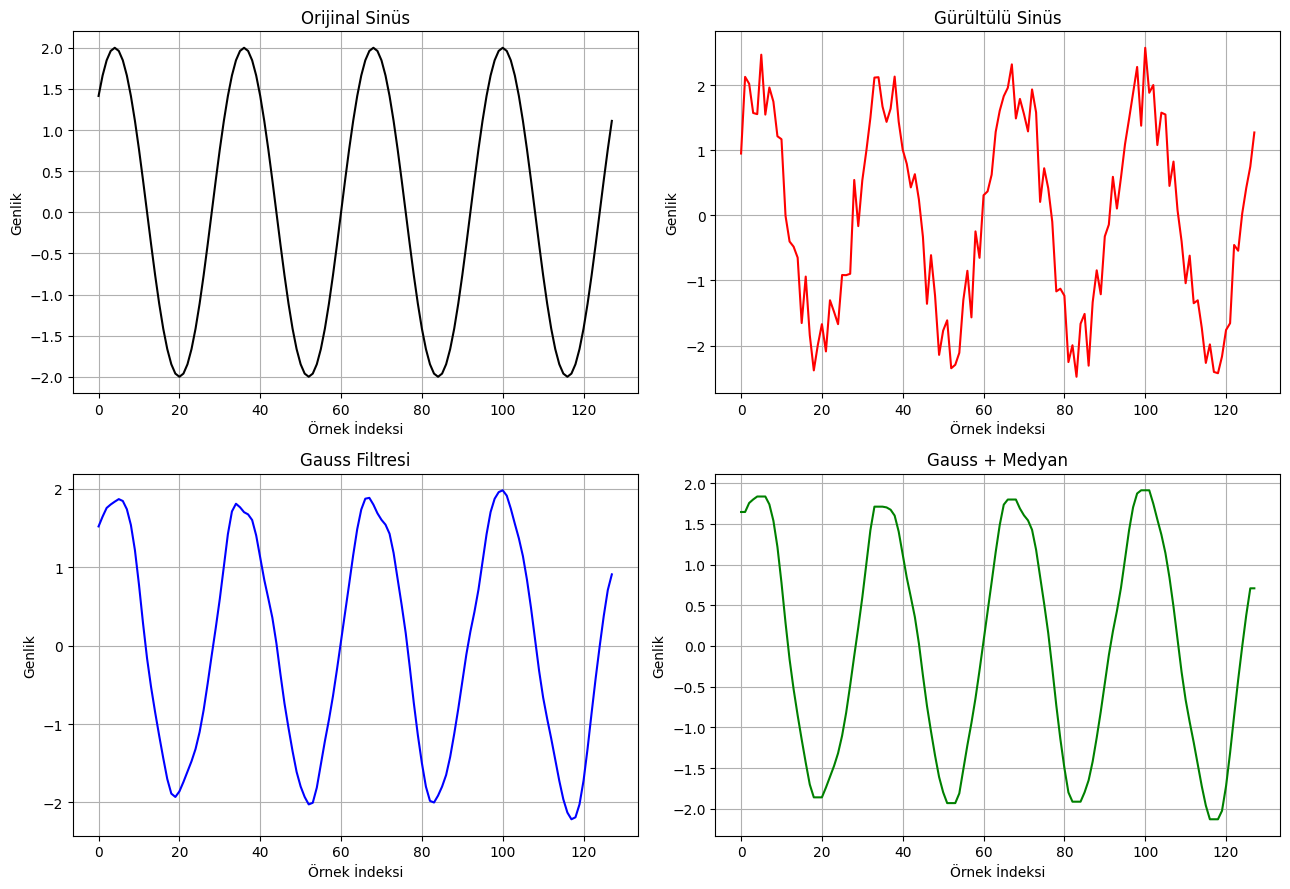

In [11]:
plt.figure(figsize=(13, 9))

sinyaller = [
    (vektor, "Orijinal Sinüs", "black"),
    (gurultulu_vektor, "Gürültülü Sinüs", "red"),
    (gauss, "Gauss Filtresi", "blue"),
    (medyan, "Gauss + Medyan", "green")
]

for i, (sinyal, baslik, renk) in enumerate(sinyaller):
    plt.subplot(2, 2, i + 1)
    plt.plot(n, sinyal, color=renk)
    plt.title(baslik)
    plt.xlabel("Örnek İndeksi")
    plt.ylabel("Genlik")
    plt.grid(True)

plt.tight_layout()
plt.savefig("odev33_sonuclar.png", dpi=200)
plt.show()

In [12]:
def rmse(a, b):
    return np.sqrt(np.mean((a - b) ** 2))

hata1 = rmse(vektor, gurultulu_vektor)
hata2 = rmse(vektor, gauss)
hata3 = rmse(vektor, medyan)

print("Gürültülü sinyal:", round(hata1, 4))
print("Gauss filtresi:", round(hata2, 4))
print("Gauss + Medyan:", round(hata3, 4))

Gürültülü sinyal: 0.356
Gauss filtresi: 0.1448
Gauss + Medyan: 0.1493


In [13]:
if hata2 < hata1:
    print("Gauss filtresi gürültünün etkisini azalttı.")
else:
    print("Gauss filtresi bu örnekte hatayı azaltamadı.")

if hata3 < hata2:
    print("Medyan filtresi ek iyileşme sağladı.")
else:
    print("Medyan filtresi ek iyileşme sağlamadı.")

print("En düşük RMSE:",
      min(hata1, hata2, hata3))

Gauss filtresi gürültünün etkisini azalttı.
Medyan filtresi ek iyileşme sağlamadı.
En düşük RMSE: 0.1447692600781677
